<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [3]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


,count
label_text,
rec.sport.hockey,600
soc.religion.christian,599
rec.motorcycles,598
rec.sport.baseball,597
sci.crypt,595
sci.med,594
rec.autos,594
sci.space,593
comp.windows.x,593


In [4]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [9]:
print(sorted(df["label_text"].unique()))

my_categories = [
    "rec.autos",
    "rec.sport.hockey",
    "sci.crypt"
]

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['rec.autos', 'rec.sport.hockey', 'sci.crypt']
Filtered dataset: 1789 documents


,count
label_text,
rec.sport.hockey,600
sci.crypt,595
rec.autos,594


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**

*(i chose these three categories because they represent different topics. thats why the vocabulary will be different since they dont share anything in common. So in conslusion the vocabulary i should have is probably going to contain something like this: sport-related terms, something related to cars and some tehcnical words)*
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [10]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [11]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    text = preprocess_basic(text)

    tokens = word_tokenize(text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    tokens = [
        word for word in tokens
        if len(word) >= 3
    ]

    return " ".join(tokens)

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [12]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

wondering anyone could enlighten car saw day door sport car looked late early called bricklin door really small addition front bumper separate rest body know anyone tellme model name engine spec year production car made history whatever info funky looking car please mail


---
# Part C – Visualization

## C.1 Most frequent words per category

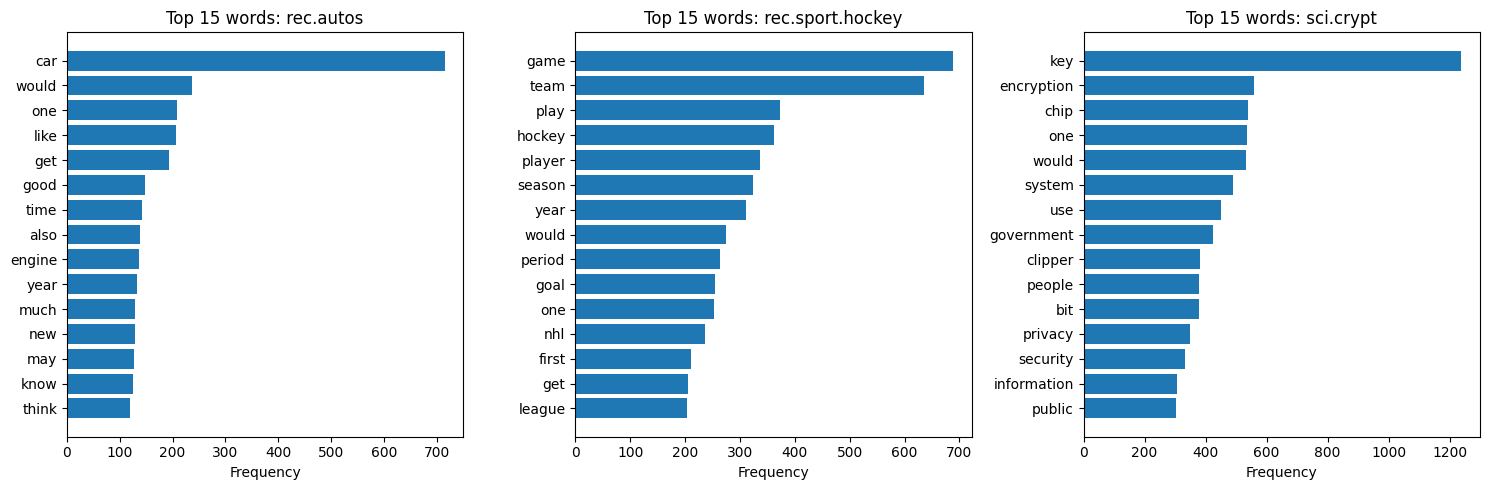

In [13]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**

*(1.  - rec.autos (car,engine,tire,driver)
  - rec.sport.hockey(hockey, player, team, season)
  - sci.crypt(encryption,key,chip,privacy)
  2. words "one" and "would" are shared by 3 categories. i think its because they are common english words, they dont really descirbe one specific topic.
  3. I think yes.)*
<!-- END ANSWER -->

## C.2 Word clouds

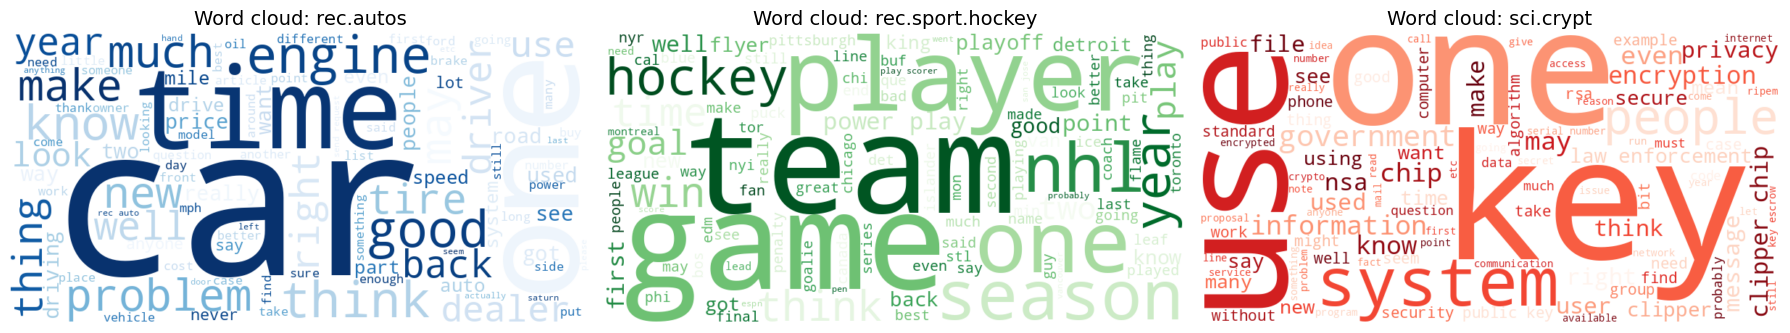

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

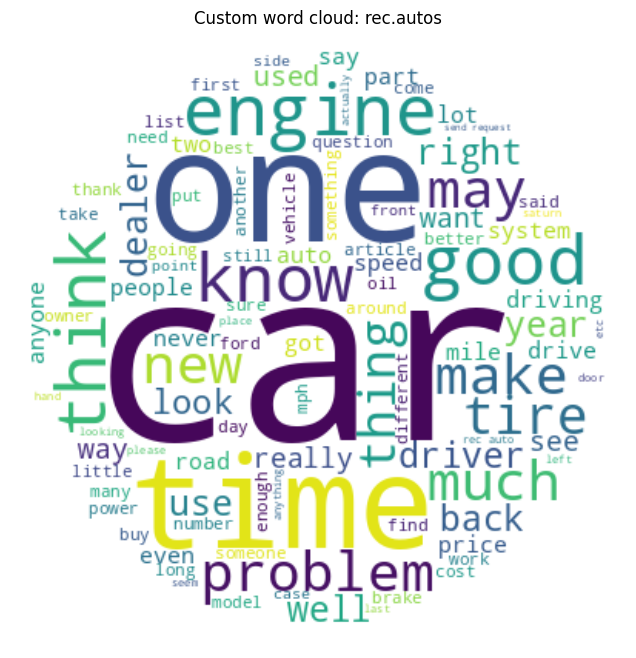

In [15]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "rec.autos"

texts = df_filtered.loc[
    df_filtered["label_text"] == selected_category,
    "text_clean"
]

text_combined = " ".join(texts)

wordcloud_masked = WordCloud(
    width=800,
    height=800,
    background_color="white",
    mask=mask,
    max_words=100
).generate(text_combined)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [16]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [17]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)

bow_matrix_full = bow_vectorizer_full.fit_transform(
    df_filtered["text_clean"]
)

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1789, 1000)
Sparsity: 96.6% of zeros
First 20 words: ['abc' 'ability' 'able' 'abuse' 'academic' 'access' 'accident' 'according'
 'account' 'acquired' 'act' 'action' 'actually' 'adam' 'add' 'addition'
 'additional' 'address' 'administration' 'administrator']


### Exercise D.2 – Document similarity

In [18]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
# 2. Find the most similar pair of distinct documents (ignore the diagonal)
similarity_matrix = cosine_similarity(bow_matrix_full)

np.fill_diagonal(similarity_matrix, -1)

most_similar_idx = np.unravel_index(
    np.argmax(similarity_matrix),
    similarity_matrix.shape
)

most_similar_score = similarity_matrix[most_similar_idx]

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1789, 1789)
Most similar documents: (np.int64(159), np.int64(558)), score = 1.000

Document 1 (rec.autos):
Hi from Australia,

I am a car enthusiast in Australia.
 
I am particularly interested in American Muscle cars of the 
1960s and 1970s. ALL MAKES: AMC, Ford, Chrysler/Mopar, GM.

I will be in the USA for 6 weeks from May 2nd to -June 14 1993.

Chicago: Sun May 2 -Thursday May 6
Denver:  Friday May 7

Document 2 (rec.autos):
Hi from Australia,

I am a car enthusiast in Australia.
 
I am particularly interested in American Muscle cars of the 
1960s and 1970s. ALL MAKES: AMC, Ford, Chrysler/Mopar, GM.

I will be in the USA for 6 weeks from May 2nd to -June 14 1993.

Chicago: Sun May 2 -Thursday May 6
Denver:  Friday May 7


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**

*(1. yes, both from rec.autos
 2. they are excactly the same, similarity score is 1.000. I think i can call them duplicates.
 3.Yes, but limited. it canidentify duplicates beacse of the wordinf , but it compares word frequencies and doesnt really understand the actual meaning. )*
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [19]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [20]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [21]:
tfidf_vectorizer_full = TfidfVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)

tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(
    df_filtered["text_clean"]
)


def get_top_tfidf_words(category, n=10):
    # 1. Find documents belonging to this category
    indices = np.where(
        df_filtered["label_text"].values == category
    )[0]

    # 2. Select their TF-IDF rows
    category_matrix = tfidf_matrix_full[indices]

    # 3. Calculate mean TF-IDF for each word
    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).flatten()

    # 4. Get the n highest-scoring words
    top_indices = mean_scores.argsort()[::-1][:n]

    feature_names = tfidf_vectorizer_full.get_feature_names_out()

    return [
        (feature_names[i], round(mean_scores[i], 4))
        for i in top_indices
    ]

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10


Top TF-IDF words for 'rec.autos':
[('car', np.float64(0.1023)), ('like', np.float64(0.0315)), ('would', np.float64(0.031)), ('engine', np.float64(0.0283)), ('one', np.float64(0.0275)), ('get', np.float64(0.0264)), ('new', np.float64(0.0245)), ('know', np.float64(0.0228)), ('good', np.float64(0.0228)), ('also', np.float64(0.0217))]

Top TF-IDF words for 'rec.sport.hockey':
[('game', np.float64(0.0741)), ('team', np.float64(0.0611)), ('player', np.float64(0.043)), ('hockey', np.float64(0.0418)), ('play', np.float64(0.034)), ('season', np.float64(0.0311)), ('year', np.float64(0.031)), ('would', np.float64(0.0289)), ('nhl', np.float64(0.0268)), ('playoff', np.float64(0.0261))]

Top TF-IDF words for 'sci.crypt':
[('key', np.float64(0.0874)), ('chip', np.float64(0.0532)), ('encryption', np.float64(0.0437)), ('clipper', np.float64(0.0426)), ('government', np.float64(0.0406)), ('would', np.float64(0.0406)), ('system', np.float64(0.0359)), ('use', np.float64(0.0318)), ('one', np.float64(0.0316

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

*(1. engine and clipper
2. one and would
3. TF-IDF captures better because it gives more importance to words and decreases importance of general words, this makes it easier to identify each category.)*
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [22]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [23]:
def top_bigrams(texts, n=15):
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        min_df=3
    )

    matrix = vectorizer.fit_transform(texts)

    counts = np.asarray(matrix.sum(axis=0)).flatten()

    bigrams = vectorizer.get_feature_names_out()

    bigram_counts = list(zip(bigrams, counts))

    return sorted(
        bigram_counts,
        key=lambda x: x[1],
        reverse=True
    )[:n]

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'rec.autos':
  rec auto: 41
  radar detector: 24
  would like: 21
  mailing list: 20
  new car: 19
  year ago: 19
  much better: 14
  sport car: 14
  look like: 13
  oil change: 13
  car driver: 12
  sound like: 12
  speed limit: 12
  car like: 11
  thing like: 11

Top bigrams for 'rec.sport.hockey':
  power play: 145
  play scorer: 63
  san jose: 62
  third period: 58
  new jersey: 56
  second period: 56
  los angeles: 55
  first period: 53
  hockey league: 52
  tampa bay: 50
  stanley cup: 49
  new york: 45
  brind amour: 42
  last year: 42
  maple leaf: 40

Top bigrams for 'sci.crypt':
  clipper chip: 194
  law enforcement: 170
  public key: 141
  key escrow: 97
  serial number: 97
  sci crypt: 73
  anonymous ftp: 63
  anonymous posting: 63
  session key: 48
  encryption technology: 45
  bit key: 43
  court order: 42
  private key: 42
  bit block: 40
  encryption algorithm: 39


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [24]:
class BigramPredictor:

    def __init__(self):
        self.bigram_counts = {}
        self.unigram_counts = Counter()

    def train(self, texts):
        for text in texts:
            tokens = str(text).split()

            for word in tokens:
                self.unigram_counts[word] += 1

            for word1, word2 in zip(tokens, tokens[1:]):
                if word1 not in self.bigram_counts:
                    self.bigram_counts[word1] = Counter()

                self.bigram_counts[word1][word2] += 1

    def predict_next(self, word, top_n=5):
        word = word.lower()

        if word not in self.bigram_counts:
            return []

        total = self.unigram_counts[word]

        predictions = [
            (next_word, count / total)
            for next_word, count in self.bigram_counts[word].items()
        ]

        return sorted(
            predictions,
            key=lambda x: x[1],
            reverse=True
        )[:top_n]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [25]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = [
    "car",
    "engine",
    "hockey",
    "team",
    "encryption"
]

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'car' ->
  driver: 0.016
  like: 0.015
  would: 0.014
  get: 0.010
  driven: 0.010

'engine' ->
  compartment: 0.034
  noise: 0.028
  running: 0.021
  run: 0.021
  configuration: 0.014

'hockey' ->
  league: 0.144
  player: 0.044
  team: 0.044
  game: 0.025
  championship: 0.025

'team' ->
  would: 0.023
  play: 0.017
  top: 0.015
  record: 0.014
  captain: 0.014

'encryption' ->
  technology: 0.081
  algorithm: 0.070
  device: 0.063
  scheme: 0.057
  system: 0.032


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

*(1. sesnible: after hockey it predicts "league" and "player", after encryption it predicts "technology" and "algorithm"
poor: afrer car it predcits "would" and "get",after engine it predicts "noise" and "compartment"
2. it considers the previous word when predicting the next one. it cannot understand the wider context, meaning or relationships between words.
 3.
- use trigrams to consider more previous words
- train model with larher datasets
- use more advanced language)*
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

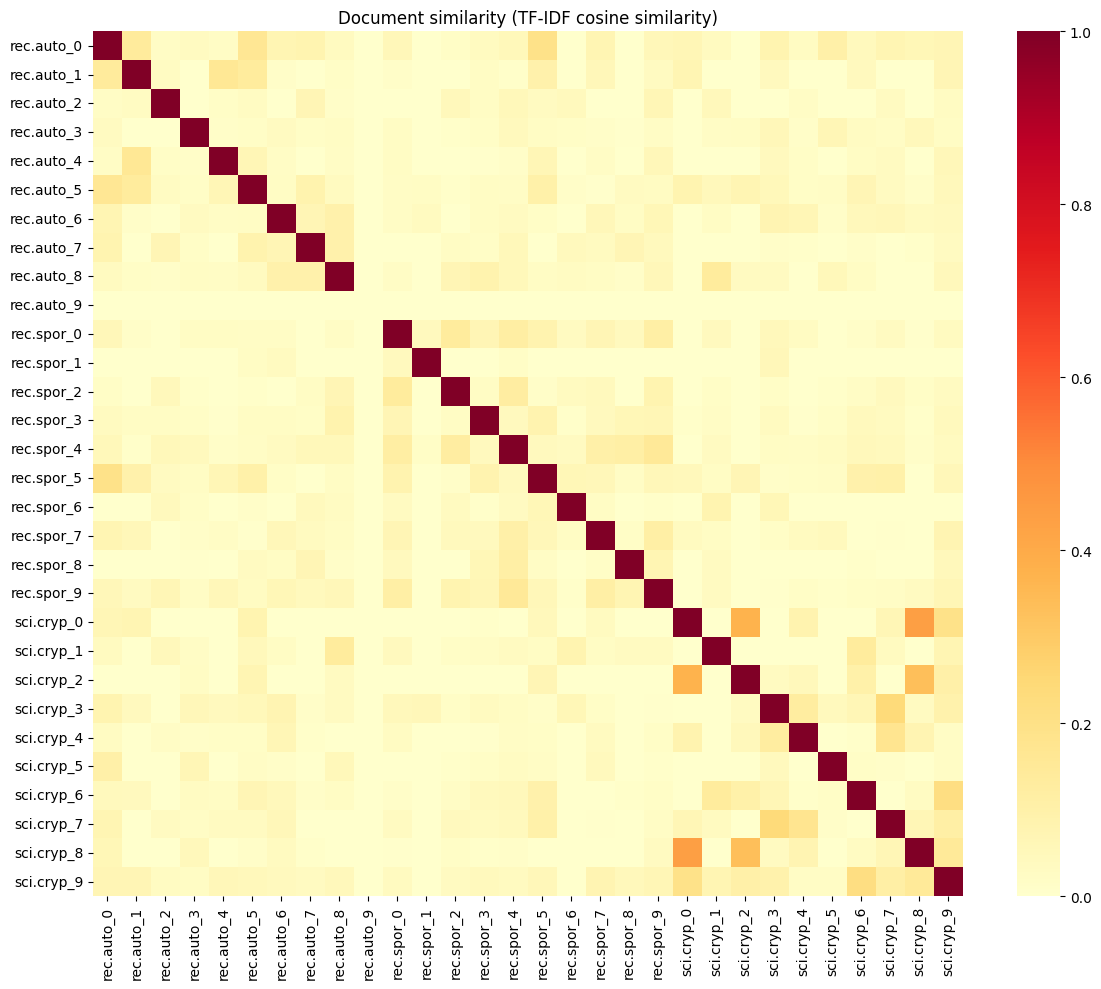

In [26]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**

*(1. yes
2. they are all separated but car and hockey are relatively similar in some areas, but car and cryptography seem less similar.
3.yes the are some, but i think it is because of general vocabulary and general technical terms. also TF-IDF reduces the influence of common words but cannot eliminate them comoletey )*
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.